# DDPG → SKRL: training semplicissimo (con segnale di stop)

Conversione del notebook originale (env "detector optimizer" + DDPG in `torchrl`) in **SKRL**.

Per avere un training *semplicissimo* e affidabile, l'ambiente e' stato semplificato rispetto all'originale, ma qui e' stato **reintrodotto il segnale di stop**:

- **Azione**: 2 componenti continue, entrambe normalizzate in `[-1, 1]`:
  - `action[0]` -> rimappata in `[50, 1000]` mm: posizione del prossimo piano.
  - `action[1]` -> se `> 0` l'agente decide di fermarsi (equivalente alla soglia 0.5 usata nell'originale su un range `[0, 1]`).
- Normalizzare entrambe le componenti nello stesso range evita che il rumore di esplorazione (stesso `std` su tutte le dimensioni, limite della `GaussianNoise` di SKRL) sia sbilanciato tra la posizione (range ampio, ~950 mm) e lo stop (range stretto).
- **Osservazione**: vettore a dimensione fissa e piccola (posizioni dei piani, paddate, + errore theta + errore beta), invece dei grandi array `(n_tracks, 20)` originali basati su un `Dict` di spazi.
- Resta comunque un limite di sicurezza (`MAX_PLANES`) che tronca l'episodio se l'agente non impara mai a fermarsi da solo.
- La fisica della simulazione (`simulate_tracks`) e la valutazione (calcolo di beta/theta ricostruiti) sono **identiche** all'originale.


In [ ]:
import numpy as np
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn

## Simulazione del detector

Stesse funzioni `simulate_tracks` e valutazione (beta/theta ricostruiti) del notebook originale, solo `eval_sim` è stata estratta come funzione libera invece che come metodo privato della classe.

In [ ]:
def simulate_tracks(
    n_planes, spatial_resolution, n_tracks=1000, plane_size=100.0,
    start_area_fraction=0.10, z_min=0.0, z_max=1000.0, z_planes=None,
    theta_max_deg=10.0, beta_min=0.5, beta_max=0.75, time_resolution=2.0,
    tof_margin=50.0, default_value=-999999.0, seed=42,
):
    """Simula tracce Monte Carlo attraverso i piani del detector (invariata rispetto all'originale)."""
    rng = np.random.default_rng(seed)
    c_mm_ns = 299.792458

    if z_planes is None or len(z_planes) == 0:
        z_planes = np.linspace(z_min, z_max, n_planes)
    z_planes = np.asarray(z_planes, dtype=np.float64)

    z_time_1 = z_min - tof_margin
    z_time_2 = z_max + tof_margin
    delta_z_tof = z_time_2 - z_time_1

    start_size = plane_size * np.sqrt(start_area_fraction)
    start_half_size = start_size / 2

    x0 = rng.uniform(-start_half_size, start_half_size, n_tracks)
    y0 = rng.uniform(-start_half_size, start_half_size, n_tracks)

    theta_max = np.deg2rad(theta_max_deg)
    phi = rng.uniform(0, 2 * np.pi, n_tracks)
    cos_theta = rng.uniform(np.cos(theta_max), 1, n_tracks)
    theta = np.arccos(cos_theta)
    theta_deg = np.rad2deg(theta)
    tan_theta = np.tan(theta)

    tx = tan_theta * np.cos(phi)
    ty = tan_theta * np.sin(phi)
    beta = rng.uniform(beta_min, beta_max, n_tracks)

    x_true = x0[:, None] + tx[:, None] * z_planes[None, :]
    y_true = y0[:, None] + ty[:, None] * z_planes[None, :]

    half_plane_size = plane_size / 2
    hit_valid = (np.abs(x_true) <= half_plane_size) & (np.abs(y_true) <= half_plane_size)

    x_meas = x_true + rng.normal(0, spatial_resolution, size=x_true.shape)
    y_meas = y_true + rng.normal(0, spatial_resolution, size=y_true.shape)
    x_meas[~hit_valid] = default_value
    y_meas[~hit_valid] = default_value

    path_length = delta_z_tof / np.cos(theta)
    delta_t_true = path_length / (beta * c_mm_ns)

    t1_meas = rng.normal(0, time_resolution, n_tracks)
    t2_meas = delta_t_true + rng.normal(0, time_resolution, n_tracks)
    delta_t_meas = t2_meas - t1_meas

    return x_meas, y_meas, z_planes, theta, theta_deg, beta, delta_t_meas, hit_valid


#Rimuovere questo step e fare in modo che la rete sia in grado di fare la stima di beta e theta direttamente dai dati misurati
def eval_sim(x_meas, y_meas, z_planes, delta_t_meas, hit_valid, n_planes):
    i_start, i_end = 0, n_planes - 1
    dx = x_meas[:, i_end] - x_meas[:, i_start]
    dy = y_meas[:, i_end] - y_meas[:, i_start]
    dz = z_planes[i_end] - z_planes[i_start]
    dr = np.sqrt(dx**2 + dy**2)
    path_length = np.sqrt(dr**2 + dz**2)

    c = 299.792458
    with np.errstate(divide="ignore", invalid="ignore"):
        beta_measured = path_length / (c * delta_t_meas)

    theta_rad_est = np.arctan2(dr, dz)
    theta_deg_est = np.degrees(theta_rad_est)

    mask = hit_valid[:, i_start] & hit_valid[:, i_end]
    beta_measured = np.where(mask, beta_measured, -5.0)
    theta_deg_est = np.where(mask, theta_deg_est, -5.0)

    return {"beta_measured": beta_measured, "theta_measured": theta_deg_est}

In [11]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

def draw_detector(
    n_planes,
    z_planes,
    plane_size=100.0,
    tof_margin=50.0,
    x_hits=None,
    y_hits=None,
    n_tracks_show=20,
    label = "Detector 3D"
):
    """
    Disegna il detector in 3D usando la coordinata fisica z
    come asse orizzontale del grafico.

    Mapping del plot:
        asse X grafico = z fisico
        asse Y grafico = x fisico
        asse Z grafico = y fisico
    """

    z_planes = z_planes[:n_planes]
    x_hits = x_hits[:, :n_planes]
    y_hits = y_hits[:, :n_planes]
    fig = plt.figure(figsize=(32, 10))
    ax = fig.add_subplot(111, projection="3d")

    half_size = plane_size / 2

    z_tracker_min = z_planes[0]
    z_tracker_max = z_planes[-1]

    z_time_1 = z_tracker_min - tof_margin
    z_time_2 = z_tracker_max + tof_margin

    def add_plane(z_phys, label, facecolor, alpha=0.25):
        """
        Piano fisico perpendicolare a z.
        Nel plot viene disegnato a X = z_phys,
        esteso lungo Y = x e Z = y.
        """

        vertices = [
            [
                (z_phys, -half_size, -half_size),
                (z_phys,  half_size, -half_size),
                (z_phys,  half_size,  half_size),
                (z_phys, -half_size,  half_size),
            ]
        ]

        plane = Poly3DCollection(
            vertices,
            facecolors=facecolor,
            edgecolors="black",
            linewidths=1.0,
            alpha=alpha
        )

        ax.add_collection3d(plane)

        ax.text(
            z_phys,
            half_size * 1.08,
            half_size * 1.08,
            label,
            fontsize=9
        )

    # Primo piano temporale
    add_plane(
        z_time_1,
        "T1",
        facecolor="tab:orange",
        alpha=0.25
    )

    # Piani di tracciamento
    for i, z in enumerate(z_planes):
        add_plane(
            z,
            f"Tracker {i}",
            facecolor="tab:blue",
            alpha=0.18
        )

    # Secondo piano temporale
    add_plane(
        z_time_2,
        "T2",
        facecolor="tab:orange",
        alpha=0.25
    )

    # Disegna alcune tracce
    if x_hits is not None and y_hits is not None:
        n_tracks = x_hits.shape[0]
        n_show = min(n_tracks_show, n_tracks)

        for i in range(n_show):
            ax.plot(
                z_planes,      # asse X grafico = z fisico
                x_hits[i],     # asse Y grafico = x fisico
                y_hits[i],     # asse Z grafico = y fisico
                marker="o",
                markersize=3,
                linewidth=1,
                alpha=0.8
            )

    # Limiti degli assi
    z_min_plot = z_time_1 - 0.1 * abs(z_time_2 - z_time_1)
    z_max_plot = z_time_2 + 0.1 * abs(z_time_2 - z_time_1)

    ax.set_xlim(z_min_plot, z_max_plot)
    ax.set_ylim(-half_size, half_size)
    ax.set_zlim(-half_size, half_size)

    ax.set_xlabel("z fisico [mm]")
    ax.set_ylabel("x fisico [mm]")
    ax.set_zlabel("y fisico [mm]")

    ax.set_title("Schema 3D del detector con asse z orizzontale")

    # Vista scelta per mostrare z orizzontale
    ax.view_init(elev=21, azim=-70)
    ax.text2D(0.02, 0.95, label, transform=ax.transAxes, fontsize=10)

    plt.tight_layout()
    plt.show()

    return fig

## Ambiente Gymnasium semplificato

- `action_space`: `Box(-1, 1, shape=(2,))` -> `action[0]` = posizione del prossimo piano (rimappata in `[50, 1000]`), `action[1]` = segnale di stop (soglia a 0).
- `observation_space`: `Box(shape=(MAX_PLANES + 2,))` -> posizioni dei piani (paddate a zero) + errore theta + errore beta.
- Episodio: termina (`terminated=True`) quando l'agente sceglie di fermarsi (e ha gia' piazzato almeno un piano); in alternativa viene troncato (`truncated=True`) dopo `MAX_PLANES` piani, come rete di sicurezza.
- Reward: stessa logica di penalita'/bonus su beta_dist/theta_dist dell'originale. Quando l'agente si ferma, quel passo non piazza un nuovo piano (come nell'originale).

In [ ]:
MAX_PLANES = 20  # rete di sicurezza: usata solo se l'agente non impara a fermarsi da solo


#Make so that the "fixed" parameters can be moved by the agent, such as spatial resolution, time resolution, and tof margin. 
class SimpleDetectorEnv(gym.Env):
    def __init__(self, n_tracks=200, spatial_res=0.1, time_res=0.3, tof_margin=50.0):
        super().__init__()
        self.n_tracks = n_tracks
        self.spatial_res = spatial_res
        self.time_res = time_res
        self.tof_margin = tof_margin
        self.max_planes = MAX_PLANES

        self.action_space = spaces.Box(low=-1.0, high=1.0, shape=(2,), dtype=np.float32)
        obs_dim = self.max_planes + 2
        self.observation_space = spaces.Box(low=-1e6, high=1e6, shape=(obs_dim,), dtype=np.float32)

        self.detector_state = np.array([], dtype=np.float32)
        self.global_seed = 42
        self.placement_range = (50.0, 1000.0)

    def _obs_and_metrics(self):
        n_planes = len(self.detector_state)
        if n_planes < 2:
            obs = np.zeros(self.observation_space.shape, dtype=np.float32)
            return obs, 999.0, 999.0, [], []

        x, y, z, theta, theta_deg, beta, dt, hit_valid = simulate_tracks(
            n_planes=n_planes, spatial_resolution=self.spatial_res,
            time_resolution=self.time_res, tof_margin=self.tof_margin,
            z_planes=self.detector_state.copy(), n_tracks=self.n_tracks,
            seed=self.global_seed,
        )
        self.global_seed += 1
        ev = eval_sim(x, y, z, dt, hit_valid.astype(bool), n_planes)
        theta_dist = float(np.linalg.norm(ev["theta_measured"] - theta_deg))
        beta_dist = float(np.linalg.norm(ev["beta_measured"] - beta))

        padded = np.zeros(self.max_planes, dtype=np.float32)
        padded[:n_planes] = self.detector_state
        obs = np.concatenate([padded, [theta_dist, beta_dist]]).astype(np.float32)
        return obs, theta_dist, beta_dist, x, y

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.detector_state = np.array([], dtype=np.float32)
        obs, _, _, _, _= self._obs_and_metrics()
        return obs, {}

    def calculate_reward(self, theta_dist, beta_dist):
        if len(self.detector_state) < 2:
            cost = 0.0
        else:
            cost = len(self.detector_state) * 2.0 + self.detector_state.max() * 0.1
        reward = 50.0 - beta_dist / 10.0 - theta_dist / 10.0 - cost
        reward += 10.0 if beta_dist < 20 else (-10.0 if beta_dist > 40 else 0.0)
        reward += 10.0 if theta_dist < 20 else (-10.0 if theta_dist > 40 else 0.0)
        return reward, cost

    def step(self, action):
        plane_position = self.placement_range[0] + (float(action[0]) + 1.0) / 2.0 * (self.placement_range[1] - self.placement_range[0])
        plane_position = float(np.clip(plane_position, self.placement_range[0], self.placement_range[1]))
        stop_signal = float(action[1])
        reward = 0.0

        should_stop = stop_signal > 0.0 and len(self.detector_state) > 0
        terminated = False
        truncated = False

        if(self.detector_state.size == self.max_planes):
            truncated = True

        if should_stop:
            terminated = True
        else:
            if plane_position not in self.detector_state and not truncated:
                self.detector_state = np.sort(np.append(self.detector_state, plane_position))

        obs, theta_dist, beta_dist, x_hits, y_hits = self._obs_and_metrics()
        if terminated or truncated:
            reward, cost = self.calculate_reward(theta_dist, beta_dist)
        return obs, float(reward)/10, terminated, truncated, {}

    
    def render(self):
        obs, _, _, x_hits, y_hits = self._obs_and_metrics()
        reward, cost = self.calculate_reward(obs[1], obs[2])
        if len(self.detector_state) < 2:
            return
        draw_detector(n_planes=len(self.detector_state), z_planes=self.detector_state, plane_size=100.0, tof_margin=50, x_hits=x_hits, y_hits=y_hits, n_tracks_show=self.n_tracks, label=f"Detector 3D - Reward: {reward:.2f}, Planes: {len(self.detector_state)}\ndist theta: {obs[1]:.2f}, dist beta: {obs[2]:.2f}\ncost: {cost:.2f}")

        

In [ ]:
from skrl.models.torch import Model, DeterministicMixin


class Actor(DeterministicMixin, Model):
    def __init__(self, observation_space, action_space, device):
        Model.__init__(self, observation_space=observation_space, action_space=action_space, device=device)
        DeterministicMixin.__init__(self, clip_actions=True)

        self.net = nn.Sequential(
            nn.Linear(self.num_observations, 2**10), nn.ReLU(),
            nn.Linear(2**10, 2**12), nn.ReLU(),
            nn.Linear(2**12, 2**10), nn.ReLU(),
            nn.Linear(2**10, self.num_actions), nn.Tanh(),
        )

    def compute(self, inputs, role=""):
        return self.net(inputs["observations"]), {}


class Critic(DeterministicMixin, Model):
    def __init__(self, observation_space, action_space, device):
        Model.__init__(self, observation_space=observation_space, action_space=action_space, device=device)
        DeterministicMixin.__init__(self, clip_actions=False)

        self.net = nn.Sequential(
            nn.Linear(self.num_observations + self.num_actions, 2**12), nn.ReLU(),
            nn.Linear(2**12, 2**10), nn.ReLU(),
            nn.Linear(2**10, 2**8), nn.ReLU(),
            nn.Linear(2**8, 1),
        )

    def compute(self, inputs, role=""):
        x = torch.cat([inputs["observations"], inputs["taken_actions"]], dim=-1)
        return self.net(x), {}


In [ ]:
from skrl.envs.wrappers.torch import wrap_env
from skrl.memories.torch import RandomMemory
from skrl.resources.noises.torch import GaussianNoise
from skrl.agents.torch.ddpg import DDPG, DDPG_CFG

device = "cpu"

env = SimpleDetectorEnv()
env = wrap_env(env)

memory = RandomMemory(memory_size=20000, num_envs=env.num_envs, device=device)

models = {
    "policy": Actor(env.observation_space, env.action_space, device),
    "target_policy": Actor(env.observation_space, env.action_space, device),
    "critic": Critic(env.observation_space, env.action_space, device),
    "target_critic": Critic(env.observation_space, env.action_space, device),
}

cfg = DDPG_CFG(
    batch_size=32,
    discount_factor=0.98,
    polyak=0.01,
    learning_rate=1e-4,
    random_timesteps=200,
    learning_starts=100,
    exploration_noise=GaussianNoise,
    exploration_noise_kwargs={"mean": 0.0, "std": 0.2, "device": device},
)
cfg.experiment.write_interval = 20
from skrl.trainers.torch import SequentialTrainer, SequentialTrainerCfg
cfg.experiment.checkpoint_interval = 0
cfg.experiment.experiment_name = "ddpg_RoT-stable"
cfg.experiment.directory = "./runs"
cfg.close_environment_at_exit = True
cfg.timesteps = 10000
cfg.disable_progressbar = False
cfg.headless = True
cfg.environment_info = True

agent = DDPG(
    models=models,
    memory=memory,
    observation_space=env.observation_space,
    action_space=env.action_space,
    device=device,
    cfg=cfg,
)


[skrl:INFO] Environment wrapper: 'auto' (class: gymnasium.core.Env)
[skrl:INFO] Environment wrapper: Gymnasium
[skrl:WARNING] Failed to check for a vectorized environment: module 'gymnasium.experimental' has no attribute 'vector'


In [ ]:
from torch.utils.tensorboard import SummaryWriter
from skrl.trainers.torch import StepTrainer

#Make custom trainer more refined, add visualization of detector config distrubution and other data
#Write description on tensorboard data, Qvalue, timesteps and so on, comment and explanations
#Write different versions of the whole system, such as Reward on Termination, and potential reward shaping, and so on
class customTrainer(StepTrainer):
    def __init__(self, env, agent, cfg):
        super().__init__(env=env, agents=agent, cfg=cfg)
        self.writer = SummaryWriter(log_dir="./runs")

    def train(self):
        self.best_reward = -np.inf

        for timestep in range(self.cfg.timesteps):
            super().train()
            
            obs = env._obs_and_metrics()
            reward, cost = env.calculate_reward(obs[1], obs[2])
            
            #print best detector state and reward if reward is better than previous best
            if reward > self.best_reward:
                self.best_reward = reward
                if(env.detector_state is not None and len(env.detector_state) > 1):
                    self.writer.add_figure("Best Detector State", draw_detector(n_planes=len(env.detector_state), z_planes=env.detector_state, plane_size=100.0, tof_margin=50, x_hits=obs[3], y_hits=obs[4], n_tracks_show=env.n_tracks, label=f"Detector 3D - Reward: {reward:.2f}, Planes: {len(env.detector_state)}\ndist theta: {obs[1]:.2f}, dist beta: {obs[2]:.2f}\ncost: {cost:.2f}"), global_step=timestep)

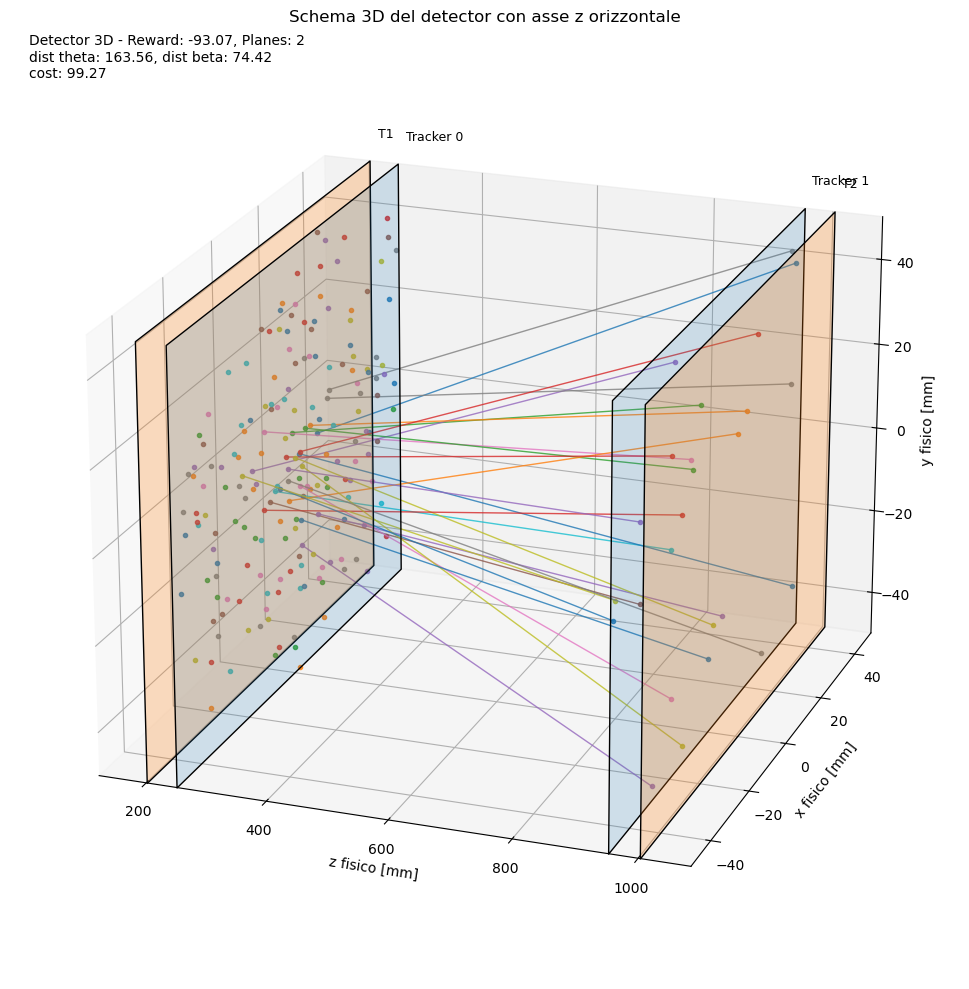

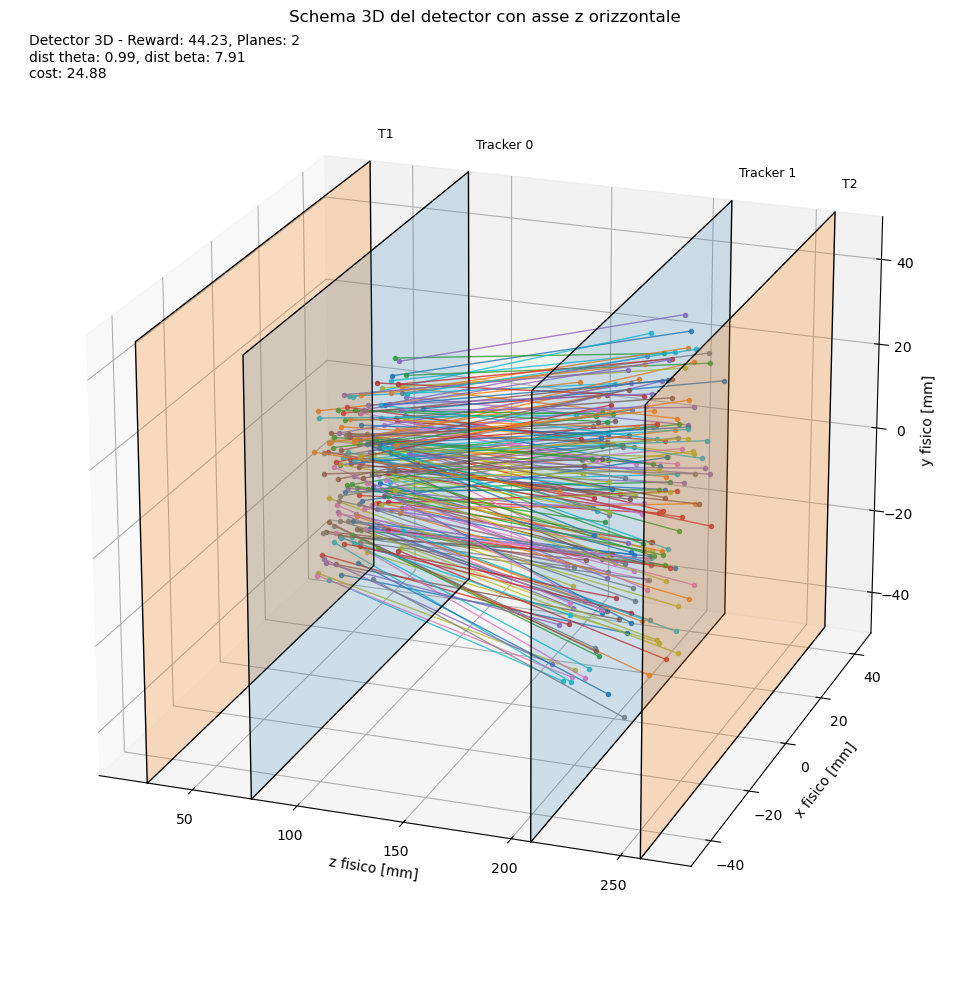

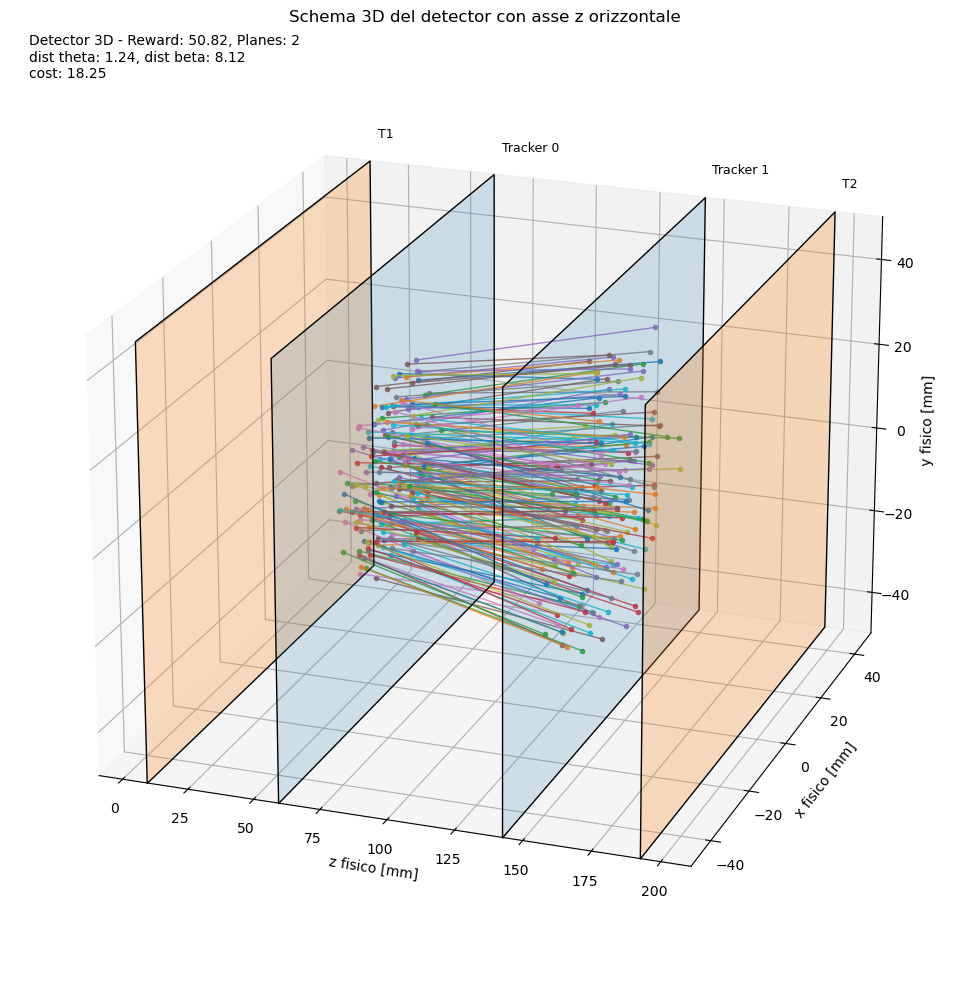

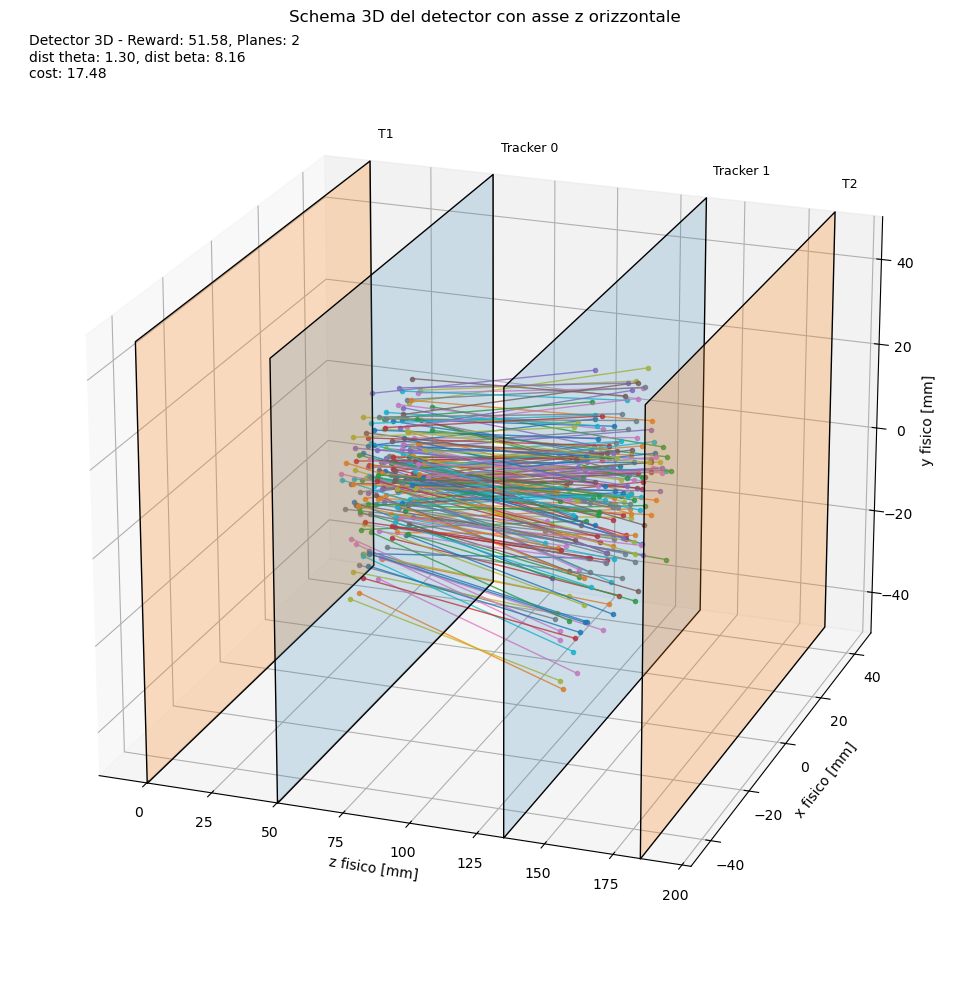

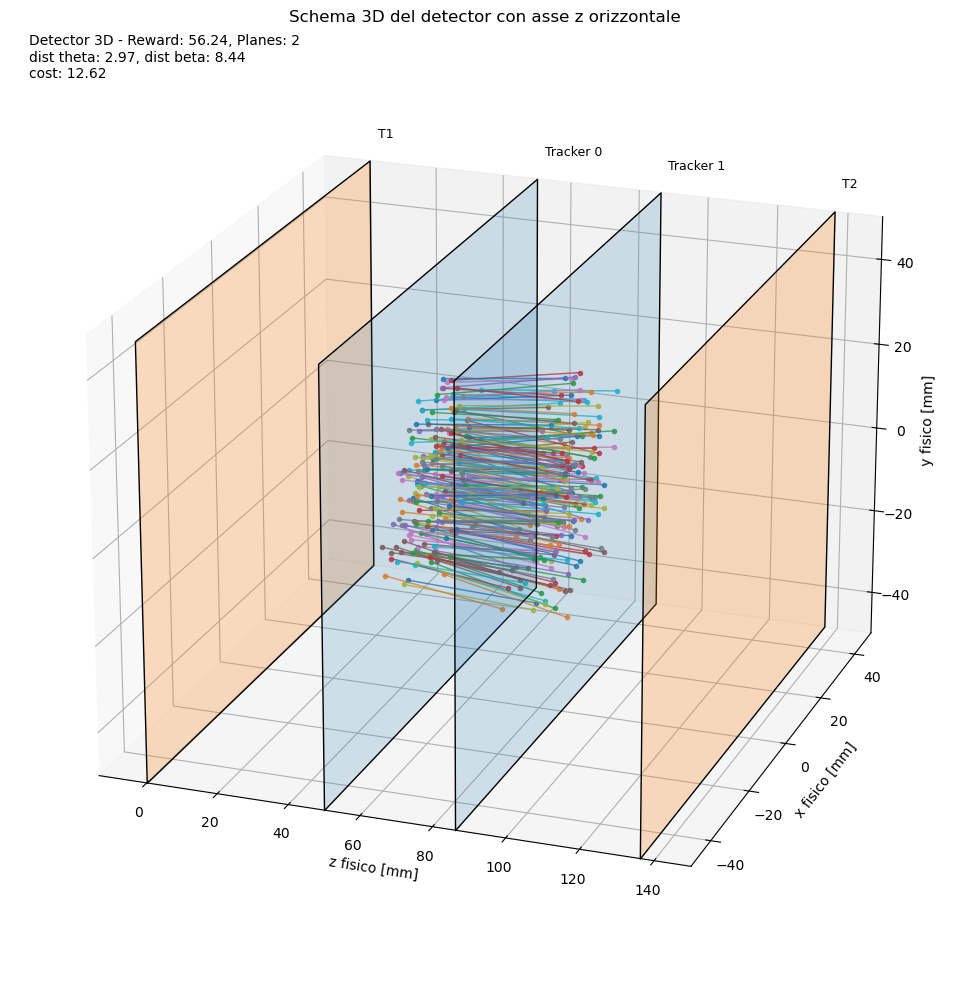

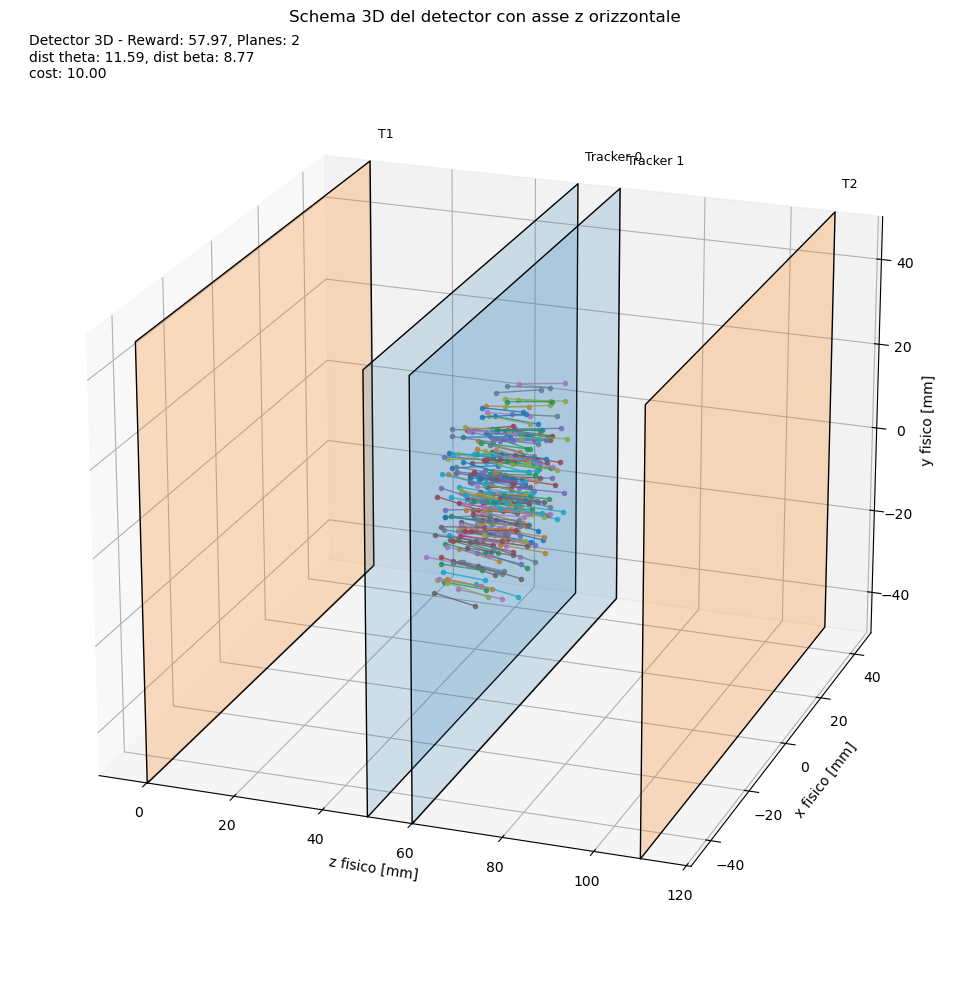

KeyboardInterrupt: 

In [16]:
customtrain = customTrainer(env=env, agent=agent, cfg=cfg)
customtrain.train()